In [ ]:
import tensorflow as tf
import keras
from tensorflow.keras.models import load_model
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import os

print(tf.__version__)
print(keras.__version__)

In [ ]:
from tensorflow.keras.layers import Layer, Dense, Conv2D, GlobalAveragePooling2D, GlobalMaxPooling2D, Reshape, Add, Activation, Multiply, Concatenate

class CBAMLayer(Layer):
    def __init__(self, ratio=8, kernel_size=7, **kwargs):
        super(CBAMLayer, self).__init__(**kwargs)
        self.ratio = ratio
        self.kernel_size = kernel_size

    def build(self, input_shape):
        self.channel = input_shape[-1]  # Get the number of channels from input shape
        
        # Define shared MLP layers for channel attention
        self.shared_dense_one = Dense(self.channel // self.ratio, activation="relu", use_bias=True, kernel_initializer="he_normal")
        self.shared_dense_two = Dense(self.channel, use_bias=True, kernel_initializer="he_normal")

        # Define the spatial attention convolutional layer
        self.spatial_conv = Conv2D(filters=1, kernel_size=self.kernel_size, strides=1, padding="same", activation="sigmoid", use_bias=False, kernel_initializer="he_normal")

        super(CBAMLayer, self).build(input_shape)  # Important to call this

    def call(self, inputs, **kwargs):
        # === Channel Attention ===
        avg_pool = GlobalAveragePooling2D()(inputs)
        max_pool = GlobalMaxPooling2D()(inputs)
        
        avg_pool = Reshape((1, 1, self.channel))(avg_pool)
        max_pool = Reshape((1, 1, self.channel))(max_pool)
        
        avg_fc = self.shared_dense_two(self.shared_dense_one(avg_pool))
        max_fc = self.shared_dense_two(self.shared_dense_one(max_pool))

        channel_attention = Activation('sigmoid')(Add()([avg_fc, max_fc]))
        channel_refined = Multiply()([inputs, channel_attention])

        # === Spatial Attention ===
        avg_spatial = tf.reduce_mean(channel_refined, axis=-1, keepdims=True)
        max_spatial = tf.reduce_max(channel_refined, axis=-1, keepdims=True)

        concat = Concatenate(axis=-1)([avg_spatial, max_spatial])
        spatial_attention = self.spatial_conv(concat)
        
        output = Multiply()([channel_refined, spatial_attention])
        return output

    def get_config(self):
        config = super(CBAMLayer, self).get_config()
        config.update({"ratio": self.ratio, "kernel_size": self.kernel_size})
        return config

In [ ]:
# Load your trained models
model1 = load_model('trained_models/vgg_2.keras', custom_objects={"CBAMLayer": CBAMLayer})
model2 = load_model('trained_models/trained_lung_cancer_model_14.keras', custom_objects={"CBAMLayer": CBAMLayer})
model3 = load_model('trained_models/google_net_2.keras', custom_objects={"CBAMLayer": CBAMLayer})

print(model1, model2, model3)

In [68]:
dataset_path = "./data_v2"
input_shape = (250, 250)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "test"),
    image_size=input_shape,  # Resize images
    batch_size=32,
    shuffle=False,
    # label_mode="categorical",
    label_mode="binary",
    color_mode="grayscale"   # only if loading grayscale images
)

data_augmentation_layer = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),  # Randomly flip images
    tf.keras.layers.RandomRotation(0.7),                   # Randomly rotate images
])

# rescale_layer = tf.keras.layers.Rescaling(1./255)  # Rescale to [0, 1]
rescale_layer = tf.keras.layers.Rescaling(1./127.5, offset=-1)  # Rescale to [-1, 1]

test_dataset = test_dataset.map(lambda x, y: (data_augmentation_layer(x), y))
test_dataset = test_dataset.map(
    lambda x, y: (rescale_layer(x), y)
)

Found 1128 files belonging to 2 classes.


In [69]:
res1 = model1.evaluate(test_dataset)
res2 = model2.evaluate(test_dataset)
res3 = model3.evaluate(test_dataset)


36/36 ━━━━━━━━━━━━━━━━━━━━ 186s 5s/step - accuracy: 0.9271 - auc: 0.5283 - f1: 0.2553 - loss: 0.1659 - precision: 0.4406 - recall: 0.4677
36/36 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.9534 - auc: 0.5319 - f1: 0.2553 - loss: 0.3399 - precision: 0.4714 - recall: 0.4980
36/36 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.9398 - auc: 0.5301 - f1: 0.2553 - loss: 2.3511 - precision: 0.4602 - recall: 0.4886


In [70]:
y_true = []
for images, labels in test_dataset:
    y_true.extend(labels.numpy())  # Convert tensor to NumPy


In [71]:
pred_1 = model1.predict(test_dataset)
pred_2 = model2.predict(test_dataset)
pred_3 = model3.predict(test_dataset)

36/36 ━━━━━━━━━━━━━━━━━━━━ 201s 6s/step
36/36 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step
36/36 ━━━━━━━━━━━━━━━━━━━━ 51s 1s/step


In [ ]:
import pandas as pd

gg = np.array(y_true).flatten()
pred_1 = np.array(pred_1).flatten()
pred_2 = np.array(pred_2).flatten()
pred_3 = np.array(pred_3).flatten()


print(len(gg), len(pred_1), len(pred_2), len(pred_3))
print(type(gg), type(pred_1), type(pred_2), type(pred_3))

# Create dataframe
df = pd.DataFrame({
    'y_true': gg,
    'pred_1': pred_1, 
    'pred_2': pred_2,
    'pred_3': pred_3
})

# Perform majority voting across the predictions
df['ensemble_pred'] = (df[['pred_1', 'pred_2', 'pred_3']].mean(axis=1) > 0.5).astype(int)
# Compare y_true and ensemble predictions
print("True values:", df['y_true'].values)
print("Ensemble predictions:", df['ensemble_pred'].values)

# Calculate accuracy
accuracy = (df['y_true'] == df['ensemble_pred']).mean()
print(f"Accuracy: {accuracy:.4f}")


df

1128 1128 1128 1128
<class 'numpy.ndarray'> <class 'numpy.ndarray'> <class 'numpy.ndarray'> <class 'numpy.ndarray'>
True values: [0. 0. 0. ... 1. 1. 1.]
Ensemble predictions: [0 0 0 ... 1 1 1]
Accuracy: 0.9459


,y_true,pred_1,pred_2,pred_3,ensemble_pred
0,0.0,0.003193,0.000305,0.010195,0
1,0.0,0.166772,0.118344,0.641947,0
2,0.0,0.037539,0.119262,0.106982,0
3,0.0,0.007041,0.000039,0.001256,0
4,0.0,0.002707,0.004513,0.247831,0
...,...,...,...,...,...
1123,1.0,0.999781,0.999998,0.999999,1
1124,1.0,0.952278,0.985300,0.997304,1
1125,1.0,0.289117,0.944582,0.957407,1
1126,1.0,0.999550,0.999198,0.990510,1


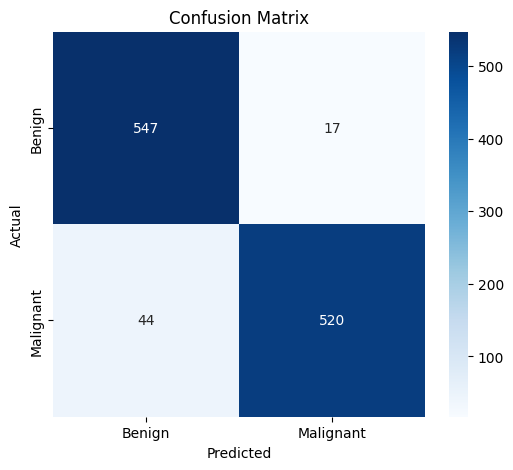

In [79]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get predictions
# y_pred = (model.predict(X_test) > 0.5).astype("int32")  # Convert probabilities to 0/1
cm = confusion_matrix(y_true, df["ensemble_pred"])

# Plot confusion matrix
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [80]:
from sklearn.metrics import classification_report

print(classification_report(y_true, df["ensemble_pred"], target_names=['Benign', 'Malignant']))


              precision    recall  f1-score   support

      Benign       0.93      0.97      0.95       564
   Malignant       0.97      0.92      0.94       564

    accuracy                           0.95      1128
   macro avg       0.95      0.95      0.95      1128
weighted avg       0.95      0.95      0.95      1128



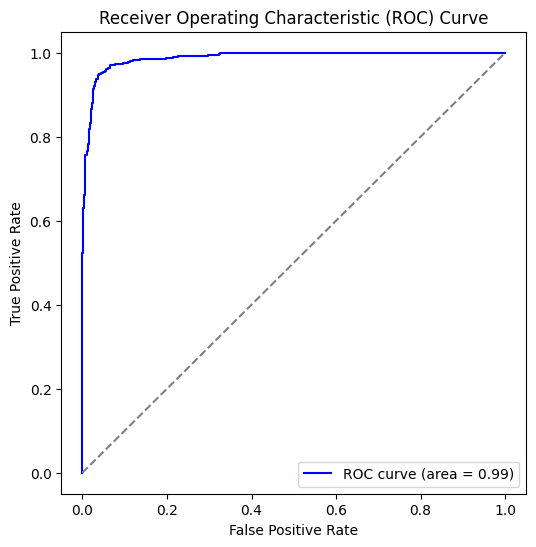

In [82]:
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities
# y_prob = model.predict(X_test).ravel()  # Flatten array

# Compute ROC curve
pred_mean = np.mean([pred_1, pred_2, pred_3], axis=0)
fpr, tpr, thresholds = roc_curve(y_true, pred_mean)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal reference line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()
